## We have tried hybrid approach of checking Date conversion into Month wise mapping.
## This approach has been tried to check how our dataset works between Date conversion (Season Mapping) and Date conversion (Month mapping)

1. **Data Loading and Inspection**:
   - The dataset is loaded from an Excel file (`Merged_Rainfall_Related_Data.xlsx`).
   - A copy of the raw dataset is saved for future use.

2. **Mapping Seasons to Mont (Season Approach)hs**:
   - A mapping is created from months (1 to 12) to respective seasons (e.g., Winter, Pre-Summer, etc.).
   - The month is extracted from the `Date` column, and a new column `Season` is added, which assigns the appropriate season based month. on the

- **Hybrid Appr (Month Approach)oach**:
        - **Season Mapping Removed**: The part where the months were mapped to seasons (e.g., `Winter`, `Pre-Summer`) was removed.
        - **Month Extraction and Encoding**:
               - The `Date` column is now converted to a `Month` using `.dt.month`.
               - The `Month` column is then one-hot encoded using `pd.get_dummies`, where each month (1-12) gets its own dummy column.
       - **Features Updated**:
               - Instead of using season columns, the model now uses columns for the months, named `Month_1` through `Month_12`, in the feature set. month.

3. **One-Hot Encoding of Seasons**:
   - The `Season` column is one-hot encoded, and dummy columns are added for each season.
   - If any season column is missing, it is added with zeros to ensure consistent columns across all data points.

4. **Adding Distance Features**:
   - New features are created to calculate the distance from the equator (`Distance_from_equator`) and the distance from the meridian (`Distance_from_meridian`) based on latitude and longitude.

5. **Feature Scaling**:
   - The numerical features (`Distance_from_equator`, `Distance_from_meridian`, etc.) are scaled using `StandardScaler` to ensure that the model can learn effectively.

6. **Model Setup**:
   - The features and target variable (`Precipitation(mm)_IMD`) are defined.
   - The dataset is split into training and testing sets using `train_test_split` (80% training, 20% testing).

7. **Model Selection and Hyperparameter Tuning**:
   - A dictionary (`param_grids`) is defined, containing different hyperparameter grids for models like Random Forest, Gradient Boosting, Decision Trees, XGBoost, and MLP (Neural Networks).
   - `RandomizedSearchCV` is used to perform a randomized search for the best hyperparameters on each model, performing cross-validation (`cv=3`), and optimizing based on the `neg_mean_squared_error`.

8. **Training and Evaluation**:
   - For each model, the best estimator (trained model) is saved, and the model is used to predict the test data (`X_test`).
   - Various performance metrics are computed:
     - **MSE**: Mean Squared Error
     - **RMSE**: Root Mean Squared Error
     - **MAE**: Mean Absolute Error
     - **R²**: R-squared (explained variance)

9. **Model Comparison**:
   - The results (metrics and training duration) for all models are printed, and the best-performing model (based on MSE) is identified.
   - The best model's training duration is also recorded.

10. **Saving Predictions**:
   - The model's predictions for the entire dataset (both training and test sets) are appended to the original dataset along with the error (absolute difference between actual and predicted values).
   - The results are saved into two Excel files:
     - **`Random Forest_Predictions_and_Error.xlsx`**: Contains predictions and errors for the entire dataset.
     - **`Random Forest_testresults.xlsx`**: Contains actual vs predicted values for the test dataset, along with the error.

### Algorithm Breakdown:

1. **Preprocessing**:
   - Map months to seasons.
   - One-hot encode the season column, ensuring all seasonal columns are present.
   - Add distance-related features (`Distance_from_equator` and `Distance_from_meridian`).
   - Scale numerical features.

2. **Model Training and Hyperparameter Tuning**:
   - Split the data into training and test sets.
   - For each model, perform `RandomizedSearchCV` to find the best hyperparameters.
   - Train the model on the training set using the best hyperparameters.

3. **Model Evaluation**:
   - After training, use the model to predict the test data.
   - Compute performance metrics (MSE, RMSE, MAE, R²) to evaluate model accuracy.

4. **Output Results**:
   - Save the model predictions, actual values, and errors in two separate Excel files for further analysis.

### Key Libraries Used:
- **Pandas**: For data manipulation and reading from Excel files.
- **NumPy**: For numerical operations, such as absolute values and array handling.
- **Scikit-learn**: For model training (`RandomForestRegressor`, `GradientBoostingRegressor`, etc.), hyperparameter tuning (`RandomizedSearchCV`), and evaluation metrics (MSE, RMSE, etc.).
- **XGBoost**: For training an XGBoost model.
- **MLPRegressor**: For training a Multi-layer Perceptron (Neural Network) model.

### Insights:
- **RandomizedSearchCV** allows you to tune multiple models efficiently without exhaustive grid search.
- The use of scaling ensures that features like precipitation and temperature, which may have different scales, do not disproportionately affect the model training.
- Saving both predicted and actual values, along with errors, helps in post-modeling analysis and can be used to track model performance over time.tions and seasons based on historical data.

In [2]:
# Date into Month Conversion

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings

warnings.filterwarnings("ignore")

# Load the dataset
file_path = 'Merged_Rainfall_Related_Data.xlsx'
data = pd.read_excel(file_path, engine='openpyxl')
# Save a copy of the original dataset for the first Excel output
original_data = data.copy()
print("Raw Data: ")
print(data)

# Convert 'Date' to datetime and extract the month
data['Month'] = pd.to_datetime(data['Date']).dt.month


# One-hot encode 'Month' column
data = pd.get_dummies(data, columns=['Month'], prefix='Month', drop_first=False)

# Add distance features
data['Distance_from_equator'] = np.abs(data['Latitude'])
data['Distance_from_meridian'] = np.abs(data['Longitude'])

# Scale numerical features for training
scaler = StandardScaler()
numeric_features = [
    'Distance_from_equator', 'Distance_from_meridian', 
    'Precipitation(mm)_NASA', 'Temperature(T2M)', 
    'Humidity(RH2M)'
]
data[numeric_features] = scaler.fit_transform(data[numeric_features])

# Define features and target
month_features = [f'Month_{month}' for month in range(1, 13)]  # Columns for months 1 to 12
features = numeric_features + month_features
target = 'Precipitation(mm)_IMD'

# Train-test split
X = data[features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("After Extracting Month: ")
print(X)

# Define model parameters for RandomizedSearchCV
param_grids = {
    'RandomForest': {
        'n_estimators': [50, 100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5],
    },
    'GradientBoosting': {
        'n_estimators': [50, 100],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 5]
    },
    'DecisionTree': {
        'max_depth': [5, 10, None],
        'min_samples_split': [2, 5]
    },
    'XGBoost': {
        'n_estimators': [50, 100],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 5]
    },
    'MLPRegressor': {
        'hidden_layer_sizes': [(50,), (100,)],
        'activation': ['relu'],
        'solver': ['adam'],
        'max_iter': [200]
    }
}

# Initialize models
models = {
    'RandomForest': RandomForestRegressor(random_state=42),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'MLPRegressor': MLPRegressor(random_state=42)
}

import time

# Perform RandomizedSearchCV and train the best models
best_estimators = {}
results = {}

for model_name, model in models.items():
    #print(f"Performing RandomizedSearchCV for {model_name}...")
    start_time = time.time() # Start timing
    search = RandomizedSearchCV(model, param_distributions=param_grids[model_name], n_iter=10, cv=3,
                                scoring='neg_mean_squared_error', random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    best_model = search.best_estimator_
    best_estimators[model_name] = best_model

    # Predict and evaluate the model
    y_pred = best_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    end_time = time.time()  # End timing
    duration = end_time - start_time  # Compute duration

    # Store results
    results[model_name] = {
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2,
        'Duration (s)': duration
    }
    

    # Print model results
    print(f"\n{model_name} Results:")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"Root Mean Squared Error (RMSE): {rmse}")
    print(f"Mean Absolute Error (MAE): {mae}")
    print(f"R-squared (R2): {r2}")
    print(f"Duration: {duration:.2f} seconds")

# Identify the best model based on MSE
best_model_name = min(results, key=lambda x: results[x]['MSE'])
best_model = best_estimators[best_model_name]
best_model_duration = results[best_model_name]['Duration (s)']  # Retrieve the duration for the best model

print(f"\nBest Model: {best_model_name} with MSE: {results[best_model_name]['MSE']}")
print(f"Training Duration for Best Model: {best_model_duration:.2f} seconds")

# First Excel output: Add predictions and error to the original dataset
original_data['Predicted_IMD_Precipitation'] = best_model.predict(X)
original_data['Error (Difference)'] = np.abs(original_data[target] - original_data['Predicted_IMD_Precipitation'])

output_file_all_data = 'Random Forest_Predictions_and_Error_month.xlsx'
original_data.to_excel(output_file_all_data, index=False)
print(f"\nRandon Forest predictions and error saved to {output_file_all_data}")

# Second Excel output: Save test data with actual vs. predicted values
test_data = X_test.copy()
test_data['Actual_IMD'] = y_test
test_data['Predicted_IMD'] = best_model.predict(X_test)
test_data['Error (Difference)'] = np.abs(test_data['Actual_IMD'] - test_data['Predicted_IMD'])

output_file_test_data = 'Random Forest_testresults_month.xlsx'
test_data.to_excel(output_file_test_data, index=False)
print(f"\nPredicted test IMD values saved to {output_file_test_data}")


Raw Data: 
             Date  Latitude  Longitude  Precipitation(mm)_NASA  \
0      2010-01-01      10.5       79.3                    0.04   
1      2010-01-02      10.5       79.3                    0.24   
2      2010-01-03      10.5       79.3                    0.30   
3      2010-01-04      10.5       79.3                    0.00   
4      2010-01-05      10.5       79.3                    0.00   
...           ...       ...        ...                     ...   
204515 2023-12-27      11.2       79.7                    1.63   
204516 2023-12-28      11.2       79.7                    2.94   
204517 2023-12-29      11.2       79.7                    1.69   
204518 2023-12-30      11.2       79.7                    0.50   
204519 2023-12-31      11.2       79.7                    0.15   

        Precipitation(mm)_IMD  Temperature(T2M)  Temperature(T2M_MAX)  \
0                    0.000000             24.58                 28.07   
1                    0.000000             24.33   

In [3]:
# Date into Season Conversion
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings

warnings.filterwarnings("ignore")

# Load the dataset
file_path = 'Merged_Rainfall_Related_Data.xlsx'
data = pd.read_excel(file_path, engine='openpyxl')
# Save a copy of the original dataset for the first Excel output
original_data = data.copy()
print("Raw Data: ")
print(data)

#Mapping out specific months to correlate with their respective seasons
season_mapping = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Pre-Summer', 4: 'Pre-Summer', 5: 'Summer',
    6: 'Summer', 7: 'Southwest Monsoon', 8: 'Southwest Monsoon',
    9: 'Autumn', 10: 'Autumn', 11: 'Northeast Monsoon'
}
data['Month'] = pd.to_datetime(data['Date']).dt.month
data['Season'] = data['Month'].map(season_mapping)
print("After Mapping: ")
print(data)

# Define all possible seasons to ensure consistent feature alignment
all_seasons = ['Winter', 'Pre-Summer', 'Summer', 'Southwest Monsoon', 'Autumn', 'Northeast Monsoon']

# One-hot encode Season with consistent columns
data = pd.get_dummies(data, columns=['Season'], prefix='Season', drop_first=False)
for season in all_seasons:
    col_name = f'Season_{season}'
    if col_name not in data.columns:
        data[col_name] = 0  # Add missing seasonal columns with zeros

# Add distance features
data['Distance_from_equator'] = np.abs(data['Latitude'])
data['Distance_from_meridian'] = np.abs(data['Longitude'])

#Scale numerical features for training
scaler = StandardScaler()
numeric_features = [
    'Distance_from_equator', 'Distance_from_meridian', 
    'Precipitation(mm)_NASA', 'Temperature(T2M)', 
    'Humidity(RH2M)'
]
data[numeric_features] = scaler.fit_transform(data[numeric_features])

# Define features and target
seasonal_features = [f'Season_{season}' for season in all_seasons]
features = numeric_features + seasonal_features
target = 'Precipitation(mm)_IMD'

# Train-test split
X = data[features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Define model parameters for RandomizedSearchCV
param_grids = {
    'RandomForest': {
        'n_estimators': [50, 100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5],
    },
    'GradientBoosting': {
        'n_estimators': [50, 100],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 5]
    },
    'DecisionTree': {
        'max_depth': [5, 10, None],
        'min_samples_split': [2, 5]
    },
    'XGBoost': {
        'n_estimators': [50, 100],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 5]
    },
    'MLPRegressor': {
        'hidden_layer_sizes': [(50,), (100,)],
        'activation': ['relu'],
        'solver': ['adam'],
        'max_iter': [200]
    }
}

# Initialize models
models = {
    'RandomForest': RandomForestRegressor(random_state=42),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'MLPRegressor': MLPRegressor(random_state=42)
}

import time

# Perform RandomizedSearchCV and train the best models
best_estimators = {}
results = {}

for model_name, model in models.items():
    #print(f"Performing RandomizedSearchCV for {model_name}...")
    start_time = time.time() # Start timing
    search = RandomizedSearchCV(model, param_distributions=param_grids[model_name], n_iter=10, cv=3,
                                scoring='neg_mean_squared_error', random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    best_model = search.best_estimator_
    best_estimators[model_name] = best_model

    # Predict and evaluate the model
    y_pred = best_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    end_time = time.time()  # End timing
    duration = end_time - start_time  # Compute duration

    # Store results
    results[model_name] = {
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2,
        'Duration (s)': duration
    }
    

    # Print model results
    print(f"\n{model_name} Results:")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"Root Mean Squared Error (RMSE): {rmse}")
    print(f"Mean Absolute Error (MAE): {mae}")
    print(f"R-squared (R2): {r2}")
    print(f"Duration: {duration:.2f} seconds")

# Identify the best model based on MSE
best_model_name = min(results, key=lambda x: results[x]['MSE'])
best_model = best_estimators[best_model_name]
best_model_duration = results[best_model_name]['Duration (s)']  # Retrieve the duration for the best model

print(f"\nBest Model: {best_model_name} with MSE: {results[best_model_name]['MSE']}")
print(f"Training Duration for Best Model: {best_model_duration:.2f} seconds")

# First Excel output: Add predictions and error to the original dataset
original_data['Predicted_IMD_Precipitation'] = best_model.predict(X)
original_data['Error (Difference)'] = np.abs(original_data[target] - original_data['Predicted_IMD_Precipitation'])

output_file_all_data = 'Random Forest_Predictions_and_Error_season.xlsx'
original_data.to_excel(output_file_all_data, index=False)
print(f"\nRandon Forest predictions and error saved to {output_file_all_data}")

# Second Excel output: Save test data with actual vs. predicted values
test_data = X_test.copy()
test_data['Actual_IMD'] = y_test
test_data['Predicted_IMD'] = best_model.predict(X_test)
test_data['Error (Difference)'] = np.abs(test_data['Actual_IMD'] - test_data['Predicted_IMD'])

output_file_test_data = 'Random Forest_testresults_season.xlsx'
test_data.to_excel(output_file_test_data, index=False)
print(f"\nPredicted test IMD values saved to {output_file_test_data}")

Raw Data: 
             Date  Latitude  Longitude  Precipitation(mm)_NASA  \
0      2010-01-01      10.5       79.3                    0.04   
1      2010-01-02      10.5       79.3                    0.24   
2      2010-01-03      10.5       79.3                    0.30   
3      2010-01-04      10.5       79.3                    0.00   
4      2010-01-05      10.5       79.3                    0.00   
...           ...       ...        ...                     ...   
204515 2023-12-27      11.2       79.7                    1.63   
204516 2023-12-28      11.2       79.7                    2.94   
204517 2023-12-29      11.2       79.7                    1.69   
204518 2023-12-30      11.2       79.7                    0.50   
204519 2023-12-31      11.2       79.7                    0.15   

        Precipitation(mm)_IMD  Temperature(T2M)  Temperature(T2M_MAX)  \
0                    0.000000             24.58                 28.07   
1                    0.000000             24.33   

# Visualization

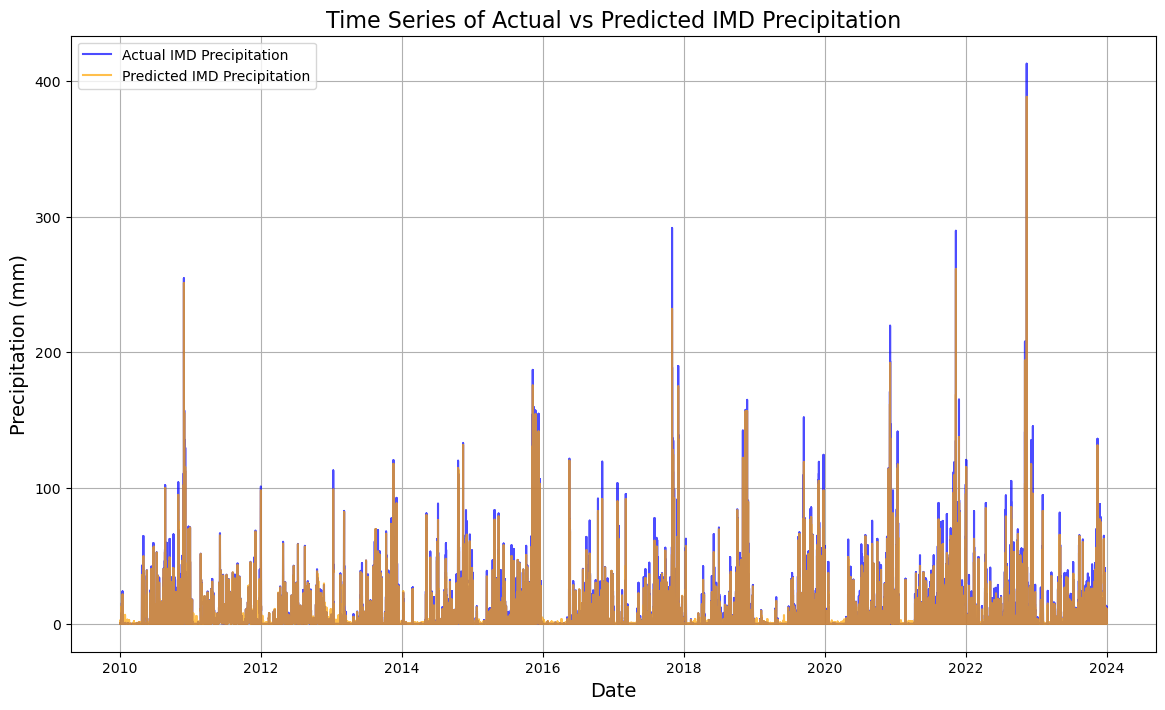

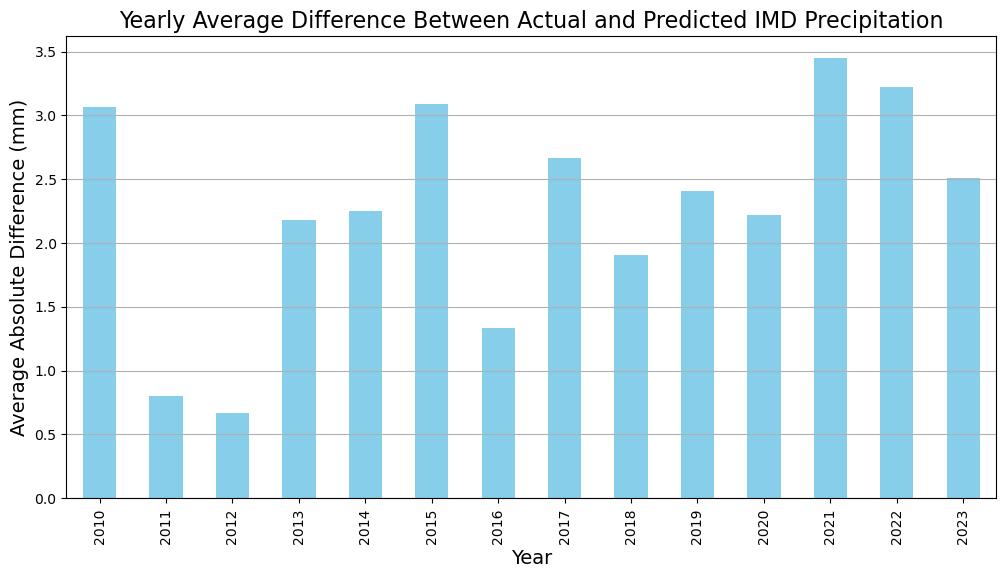


Feature Importance:
Precipitation(mm)_NASA      0.405517
Humidity(RH2M)              0.209639
Temperature(T2M)            0.187296
Distance_from_equator       0.101291
Distance_from_meridian      0.053429
Season_Northeast Monsoon    0.010228
Season_Winter               0.009676
Season_Autumn               0.008178
Season_Summer               0.005827
Season_Southwest Monsoon    0.005129
Season_Pre-Summer           0.003789
dtype: float64


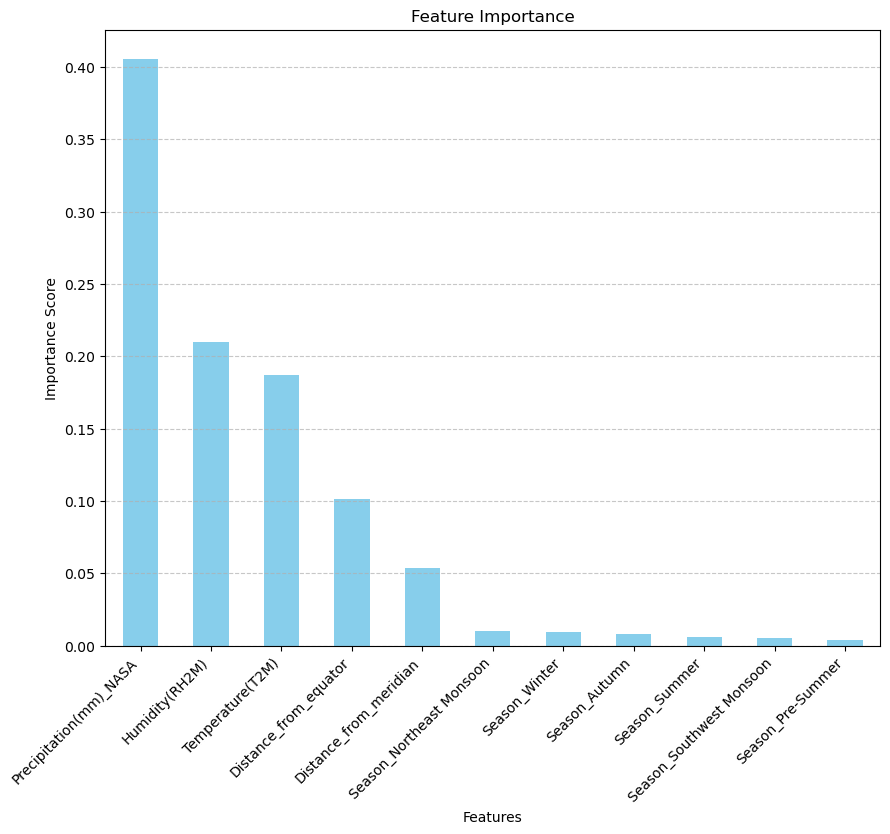

Successfully extracted 'Month' from 'Date'.


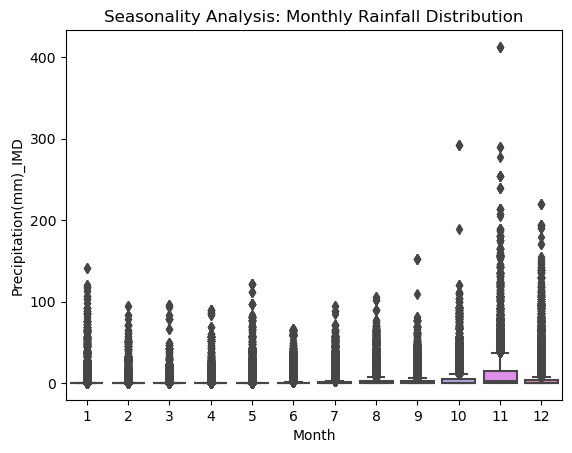

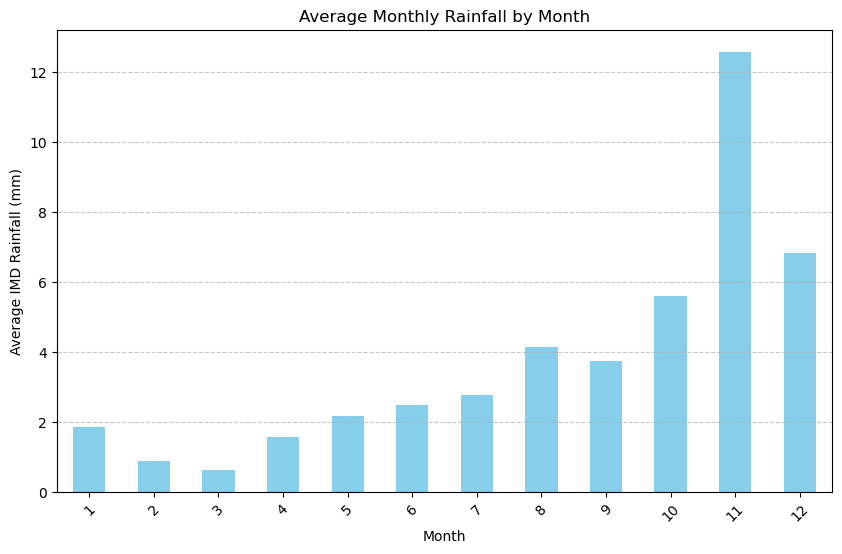

In [6]:
#Time series Visualization

import matplotlib.pyplot as plt

# Merge actual and predicted data on Date from existing datasets
merged_data = original_data[['Date', target]].merge(
    original_data[['Date', 'Predicted_IMD_Precipitation']],
    on='Date',
    how='inner'
)

# Set Date as the index for time-series plotting
merged_data['Date'] = pd.to_datetime(merged_data['Date'])
merged_data.set_index('Date', inplace=True)

# Plot the actual and predicted IMD precipitation values
plt.figure(figsize=(14, 8))
plt.plot(merged_data.index, merged_data[target], label='Actual IMD Precipitation', color='blue', alpha=0.7)
plt.plot(merged_data.index, merged_data['Predicted_IMD_Precipitation'], label='Predicted IMD Precipitation', color='orange', alpha=0.7)
plt.title('Time Series of Actual vs Predicted IMD Precipitation', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Precipitation (mm)', fontsize=14)
plt.legend()
plt.grid()
plt.show()

# Calculate yearly differences and plot
merged_data['Year'] = merged_data.index.year
yearly_difference = merged_data.groupby('Year').apply(
    lambda x: (x[target] - x['Predicted_IMD_Precipitation']).abs().mean()
)

plt.figure(figsize=(12, 6))
yearly_difference.plot(kind='bar', color='skyblue')
plt.title('Yearly Average Difference Between Actual and Predicted IMD Precipitation', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Average Absolute Difference (mm)', fontsize=14)
plt.grid(axis='y')
plt.show()


#Feature Importance Analysis
# Feature Importance Analysis for the best model (if it has feature_importances_ attribute)
if hasattr(best_model, 'feature_importances_'):
    feature_importances = pd.Series(best_model.feature_importances_, index=features).sort_values(ascending=False)
    print("\nFeature Importance:")
    print(feature_importances)

    # Feature Importance Visualization
    plt.figure(figsize=(10, 8))
    feature_importances.plot(kind='bar', color='skyblue')
    plt.title('Feature Importance')
    plt.xlabel('Features')
    plt.ylabel('Importance Score')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

#Seasonality Analysis - Boxplot
# Seasonality Boxplot
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Check if 'Date' column exists and extract 'Month' from it
if 'Date' in original_data.columns:
    try:
        # Ensure 'Date' column is in datetime format
        original_data['Date'] = pd.to_datetime(original_data['Date'], errors='coerce')
        # Extract 'Month' as a new column
        original_data['Month'] = original_data['Date'].dt.month
        print("Successfully extracted 'Month' from 'Date'.")
    except Exception as e:
        print("Error processing 'Date' column:", e)
else:
    print("'Date' column not found! Cannot extract 'Month'.")

# Check if 'Month' column was successfully created
if 'Month' in original_data.columns:
    # Convert 'Month' to categorical for better plotting
    original_data['Month'] = original_data['Month'].astype('category')

    # Debugging plot
    try:
        sns.boxplot(x='Month', y=target, data=original_data)
        plt.title('Seasonality Analysis: Monthly Rainfall Distribution')
        plt.xlabel('Month')
        plt.ylabel(target)
        plt.show()
    except Exception as e:
        print("Error generating boxplot:", e)
else:
    print("Unable to create 'Month' column. Cannot generate plot.")

#Seasonal Average Rainfall
# Seasonal Average Rainfall
seasonal_avg = original_data.groupby('Month')[target].mean()

plt.figure(figsize=(10, 6))
seasonal_avg.plot(kind='bar', color='skyblue')
plt.title('Average Monthly Rainfall by Month')
plt.xlabel('Month')
plt.ylabel('Average IMD Rainfall (mm)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



## Test Data Prediction
### User Input Option to predict IMD Precipitation

# Approach 1 Date Search Within given range

In [7]:
from datetime import datetime

# Prepare to collect prediction results
prediction_results = []

# Data for prediction
test_data = [
    {"Date": "12/19/2019", "Latitude": 11.2, "Longitude": 79.4},
    {"Date": "8/10/2023", "Latitude": 10.9, "Longitude": 79.4},
    {"Date": "8/22/2010", "Latitude": 10.5, "Longitude": 79.4},
    {"Date": "6/24/2016", "Latitude": 10.8, "Longitude": 79.4},
    {"Date": "9/20/2023", "Latitude": 10.9, "Longitude": 79.6},
    {"Date": "4/23/2011", "Latitude": 10.9, "Longitude": 79.4},
    {"Date": "8/9/2014", "Latitude": 10.8, "Longitude": 79.5},
    {"Date": "5/20/2011", "Latitude": 10.9, "Longitude": 79.4},
    {"Date": "8/23/2023", "Latitude": 10.5, "Longitude": 79.3},
    {"Date": "7/27/2016", "Latitude": 10.5, "Longitude": 79.4},
    {"Date": "12/30/2023", "Latitude": 10.8, "Longitude": 79.7},
    {"Date": "7/2/2021", "Latitude": 11, "Longitude": 79.4},
    {"Date": "10/8/2021", "Latitude": 10.5, "Longitude": 79.3},
    {"Date": "12/31/2010", "Latitude": 10.7, "Longitude": 79.4},
    {"Date": "6/15/2017", "Latitude": 11.1, "Longitude": 79.4},
    {"Date": "10/28/2017", "Latitude": 11.1, "Longitude": 79.3},
    {"Date": "1/9/2011", "Latitude": 11.1, "Longitude": 79.3},
    {"Date": "8/23/2015", "Latitude": 10.9, "Longitude": 79.3},
    {"Date": "11/5/2022", "Latitude": 10.8, "Longitude": 79.6},
    {"Date": "2/24/2014", "Latitude": 11, "Longitude": 79.4}
]

# Function for predicting IMD rainfall based on Date
def predict_imd_rainfall_by_date():
    for entry in test_data:
        date_input = entry['Date']
        latitude = entry['Latitude']
        longitude = entry['Longitude']

        # Convert date string to datetime object
        date = datetime.strptime(date_input, '%m/%d/%Y')
        month = date.month
        season = season_mapping[month]

        # Extract raw values for the given Latitude, Longitude, and Date
        filtered_data = data[
            (data['Latitude'] == latitude) &
            (data['Longitude'] == longitude) &
            (data['Date'] == date_input)
        ]

        if filtered_data.empty:
            print(f"No matching data found for the provided Latitude: {latitude}, Longitude: {longitude}, Date: {date_input}")
            continue

        # Extract actual values
        precipitation_nasa = filtered_data['Precipitation(mm)_NASA'].values[0]
        temperature_t2m = filtered_data['Temperature(T2M)'].values[0]
        humidity_rh2m = filtered_data['Humidity(RH2M)'].values[0]
        actual_imd_precipitation = filtered_data['Precipitation(mm)_IMD'].values[0]

        # Prepare input data for prediction
        distance_from_equator = abs(latitude)
        distance_from_meridian = abs(longitude)

        input_data = {
            'Distance_from_equator': [distance_from_equator],
            'Distance_from_meridian': [distance_from_meridian],
            'Precipitation(mm)_NASA': [precipitation_nasa],
            'Temperature(T2M)': [temperature_t2m],
            'Humidity(RH2M)': [humidity_rh2m]
        }

        # Add season columns to the input data
        for season_name in ['Winter', 'Pre-Summer', 'Summer', 'Southwest Monsoon', 'Autumn', 'Northeast Monsoon']:
            input_data[f'Season_{season_name}'] = [1 if season == season_name else 0]

        # Convert input data to DataFrame
        input_df = pd.DataFrame(input_data)

        # Ensure columns in `input_df` align with `features` used during training
        input_df = input_df.reindex(columns=numeric_features + [f'Season_{season}' for season in ['Winter', 'Pre-Summer', 'Summer', 'Southwest Monsoon', 'Autumn', 'Northeast Monsoon']], fill_value=0)

        # Scale the numeric features
        input_df[numeric_features] = scaler.transform(input_df[numeric_features])

        # Make prediction
        predicted_rainfall = best_model.predict(input_df)[0]

        # Collect results into a list, including actual Temperature and Humidity
        prediction_results.append({
            'Date': date_input,
            'Latitude': latitude,
            'Longitude': longitude,
            'Actual Precipitation (NASA)': precipitation_nasa,
            'Actual Temperature(T2M)': temperature_t2m,
            'Actual Humidity(RH2M)': humidity_rh2m,
            'Actual Precipitation (IMD)': actual_imd_precipitation,
            'Predicted Precipitation (IMD)': predicted_rainfall
        })

# Run the prediction function
predict_imd_rainfall_by_date()

# Convert results into a DataFrame and save to Excel
results_df = pd.DataFrame(prediction_results)
results_df.to_excel("Approach_1_Date_search.xlsx", index=False)

print("Predictions have been saved to 'Approach_1_Date_search.xlsx'.")


Predictions have been saved to 'Approach_1_Date_search.xlsx'.


# Approach 1 Season Search Within given range

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor  

# Load raw dataset (unscaled data)
raw_data_path = "Merged_Rainfall_Related_Data.xlsx"
raw_data = pd.read_excel(raw_data_path, engine='openpyxl')

# Define season mapping
season_mapping = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Pre-Summer', 4: 'Pre-Summer', 5: 'Summer',
    6: 'Summer', 7: 'Southwest Monsoon', 8: 'Southwest Monsoon',
    9: 'Autumn', 10: 'Autumn', 11: 'Northeast Monsoon'
}

# Add a "Season" column to the raw data
raw_data['Month'] = pd.to_datetime(raw_data['Date']).dt.month
raw_data['Season'] = raw_data['Month'].map(season_mapping)

# Specific locations and seasons
input_data = [
    ('Autumn', 11.2, 79.3),
    ('Autumn', 11.1, 79.7),
    ('Autumn', 10.8, 79.5),
    ('Autumn', 10.7, 79.6),
    ('Winter', 11, 79.4),
    ('Winter', 10.7, 79.6),
    ('Winter', 10.7, 79.6),
    ('Winter', 10.8, 79.7),
    ('Northeast Monsoon', 11, 79.5),
    ('Northeast Monsoon', 10.8, 79.6),
    ('Northeast Monsoon', 10.5, 79.5),
    ('Northeast Monsoon', 11.1, 79.6),
    ('Southwest Monsoon', 11.1, 79.5),
    ('Southwest Monsoon', 10.6, 79.4),
    ('Southwest Monsoon', 11.1, 79.6),
    ('Southwest Monsoon', 10.5, 79.4),
    ('Summer', 10.7, 79.4),
    ('Summer', 10.5, 79.6),
    ('Summer', 10.9, 79.5),
    ('Summer', 11, 79.5),
    ('Pre-Summer', 11.2, 79.5),
    ('Pre-Summer', 11.2, 79.6),
    ('Pre-Summer', 10.9, 79.4),
    ('Pre-Summer', 10.9, 79.6)
]

# Function for prediction based on specific inputs
def predict_imd_rainfall_for_selected_locations():
    # Create a list to store the prediction results
    prediction_results = []

    # Iterate over each specific input (season, latitude, longitude)
    for season, latitude, longitude in input_data:
        # Extract raw values for the given Latitude and Longitude
        filtered_data = raw_data[(raw_data['Latitude'] == latitude) & (raw_data['Longitude'] == longitude)]
        
        if filtered_data.empty:
            prediction_results.append({
                'Latitude': latitude,
                'Longitude': longitude,
                'Season': season,
                'Precipitation(mm)_NASA': None,
                'Precipitation(mm)_IMD': None,
                'Temperature(T2M)': None,
                'Humidity(RH2M)': None,
                'Predicted_IMD_Rainfall': None,
                'Message': "No matching data found for the provided Latitude and Longitude"
            })
            continue
        
        # Filter by season and calculate averages
        season_data = filtered_data[filtered_data['Season'] == season]
        
        if season_data.empty:
            prediction_results.append({
                'Latitude': latitude,
                'Longitude': longitude,
                'Season': season,
                'Precipitation(mm)_NASA': None,
                'Precipitation(mm)_IMD': None,
                'Temperature(T2M)': None,
                'Humidity(RH2M)': None,
                'Predicted_IMD_Rainfall': None,
                'Message': "No matching data found for the season at the provided location"
            })
            continue
        
        # Calculate average values for the given season
        precipitation_nasa = season_data['Precipitation(mm)_NASA'].mean()
        precipitation_imd = season_data['Precipitation(mm)_IMD'].mean()
        temperature_t2m = season_data['Temperature(T2M)'].mean()
        humidity_rh2m = season_data['Humidity(RH2M)'].mean()
        
        # Prepare input data for prediction
        distance_from_equator = abs(latitude)
        distance_from_meridian = abs(longitude)
        
        input_data_for_prediction = {
            'Distance_from_equator': [distance_from_equator],
            'Distance_from_meridian': [distance_from_meridian],
            'Precipitation(mm)_NASA': [precipitation_nasa],
            'Temperature(T2M)': [temperature_t2m],
            'Humidity(RH2M)': [humidity_rh2m]
        }
        
        # Add season columns to the input data
        for season_name in ['Winter', 'Pre-Summer', 'Summer', 'Southwest Monsoon', 'Autumn', 'Northeast Monsoon']:
            input_data_for_prediction[f'Season_{season_name}'] = [1 if season == season_name else 0]

        # Convert input data to DataFrame
        input_df = pd.DataFrame(input_data_for_prediction)

        # Ensure columns in `input_df` align with `numeric_features` used during training
        input_df = input_df.reindex(columns=numeric_features + [f'Season_{season_name}' for season_name in ['Winter', 'Pre-Summer', 'Summer', 'Southwest Monsoon', 'Autumn', 'Northeast Monsoon']], fill_value=0)

        # Scale the numeric features (assuming scaler is available)
        input_df[numeric_features] = scaler.transform(input_df[numeric_features])

        # Make prediction (assuming model is available)
        predicted_rainfall = best_model.predict(input_df)[0]
        
        # Add the results to the list
        prediction_results.append({
            'Latitude': latitude,
            'Longitude': longitude,
            'Season': season,
            'Precipitation(mm)_NASA': precipitation_nasa,
            'Precipitation(mm)_IMD': precipitation_imd,
            'Temperature(T2M)': temperature_t2m,
            'Humidity(RH2M)': humidity_rh2m,
            'Predicted_IMD_Rainfall': predicted_rainfall,
            'Message': "Prediction successful"
        })
    
    # Convert results into a DataFrame
    results_df = pd.DataFrame(prediction_results)
    
    # Save results to Excel
    results_df.to_excel("Approach_1_Season_search.xlsx", index=False)
    
    print("Predictions have been saved to 'Approach_1_Season_search.xlsx'.")

# Run the prediction function
predict_imd_rainfall_for_selected_locations()


Predictions have been saved to 'Approach_1_Season_search.xlsx'.


# Approach 2 Date Search Outside range

In [10]:
import pandas as pd
from datetime import datetime
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Sample data for training (replace this with your actual dataset)
data = "Merged_Rainfall_Related_Data.xlsx"
data = pd.read_excel(data, engine='openpyxl')

# Prepare the season mapping based on the month
season_mapping = {
    1: 'Winter', 2: 'Winter', 3: 'Pre-Summer', 4: 'Pre-Summer', 5: 'Pre-Summer', 6: 'Summer',
    7: 'Summer', 8: 'Southwest Monsoon', 9: 'Southwest Monsoon', 10: 'Autumn', 11: 'Autumn', 12: 'Winter'
}

# Feature engineering: Extract season and map it to the data
data['Date'] = pd.to_datetime(data['Date'], format='%m/%d/%Y')  # Ensure your Date column is in datetime format
data['Month'] = data['Date'].dt.month
data['Season'] = data['Month'].map(season_mapping)

# Extract year, month, and day from the Date column as numeric features
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Day'] = data['Date'].dt.day

# Prepare features and target variable
features = ['Latitude', 'Longitude', 'Precipitation(mm)_NASA', 'Temperature(T2M)', 'Humidity(RH2M)', 'Year', 'Month', 'Day']
target = 'Precipitation(mm)_IMD'

# Encode season as categorical variables (one-hot encoding)
data = pd.get_dummies(data, columns=['Season'], drop_first=True)

# Define features (X) and target (y)
X = data.drop(columns=[target, 'Date'])  # Drop the target and Date columns
y = data[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a RandomForest model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# Now, let's predict for the given input data:
#year-mm-dd
input_data = [
    {'Date': '2011-01-01 00:00:00', 'Latitude': 10.999226, 'Longitude': 79.479101, 
     'Precipitation(mm)_NASA': 0.08, 'Temperature(T2M)': 26.96, 'Humidity(RH2M)': 75.69},
    
    {'Date': '2012-02-02 00:00:00', 'Latitude': 10.999226, 'Longitude': 79.479101, 
     'Precipitation(mm)_NASA': 0.6, 'Temperature(T2M)': 30.55, 'Humidity(RH2M)': 65.38},
    
    {'Date': '2013-03-03 00:00:00', 'Latitude': 11.1691, 'Longitude': 79.479101, 
     'Precipitation(mm)_NASA': 0.15, 'Temperature(T2M)': 31.83, 'Humidity(RH2M)': 56.44},
    
    {'Date': '2014-04-04 00:00:00', 'Latitude': 11.1691, 'Longitude': 79.479101, 
     'Precipitation(mm)_NASA': 0.21, 'Temperature(T2M)': 29.11, 'Humidity(RH2M)': 65.44},
    
    {'Date': '2015-05-05 00:00:00', 'Latitude': 11.1691, 'Longitude': 79.53421, 
     'Precipitation(mm)_NASA': 0.53, 'Temperature(T2M)': 29.65, 'Humidity(RH2M)': 67.56},
    
    {'Date': '2016-06-06 00:00:00', 'Latitude': 11.1691, 'Longitude': 79.53421, 
     'Precipitation(mm)_NASA': 1.9, 'Temperature(T2M)': 27.12, 'Humidity(RH2M)': 84.56}
]

# Prepare to collect prediction results
prediction_results = []

# Function to predict IMD rainfall based on Date, Latitude, Longitude, Precipitation, Temperature, and Humidity
def predict_imd_rainfall_by_date():
    for entry in input_data:
        date_input = entry['Date']
        latitude = entry['Latitude']
        longitude = entry['Longitude']
        precipitation_nasa = entry['Precipitation(mm)_NASA']
        temperature_t2m = entry['Temperature(T2M)']
        humidity_rh2m = entry['Humidity(RH2M)']

        # Convert date string to datetime object
        date = datetime.strptime(str(date_input), '%Y-%m-%d %H:%M:%S')
        year = date.year
        month = date.month
        day = date.day

        # Map season based on month
        season = season_mapping[month]

        # Prepare input data for prediction
        distance_from_equator = abs(latitude)
        distance_from_meridian = abs(longitude)

        input_features = {
            'Distance_from_equator': [distance_from_equator],
            'Distance_from_meridian': [distance_from_meridian],
            'Precipitation(mm)_NASA': [precipitation_nasa],
            'Temperature(T2M)': [temperature_t2m],
            'Humidity(RH2M)': [humidity_rh2m],
            'Year': [year],
            'Month': [month],
            'Day': [day]
        }

        # Add season columns to the input data
        for season_name in ['Winter', 'Pre-Summer', 'Summer', 'Southwest Monsoon', 'Autumn', 'Northeast Monsoon']:
            input_features[f'Season_{season_name}'] = [1 if season == season_name else 0]

        # Convert input data to DataFrame
        input_df = pd.DataFrame(input_features)

        # Ensure columns align with training features
        input_df = input_df.reindex(columns=X.columns, fill_value=0)

        # Scale the numeric features using the same scaler
        input_df_scaled = scaler.transform(input_df)

        # Make prediction using the trained model
        predicted_rainfall = model.predict(input_df_scaled)[0]

        # Collect results into a list
        prediction_results.append({
            'Date': date_input,
            'Latitude': latitude,
            'Longitude': longitude,
            'Precipitation(mm)_NASA': precipitation_nasa,
            'Temperature(T2M)': temperature_t2m,
            'Humidity(RH2M)': humidity_rh2m,
            'Predicted Precipitation (IMD)': predicted_rainfall
        })

# Run the prediction function
predict_imd_rainfall_by_date()

# Convert results into a DataFrame and save to Excel
results_df = pd.DataFrame(prediction_results)
results_df.to_excel("Approach_2_Date_search.xlsx", index=False)

print("Predictions have been saved to 'Approach_2_Date_search.xlsx'.")


Predictions have been saved to 'Approach_2_Date_search.xlsx'.


# Approach 2 Season Search Outside range

In [12]:
import pandas as pd
from datetime import datetime
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Step 1: Load training dataset (Merged_Rainfall_Related_Data.xlsx)
merged_data_path = "Merged_Rainfall_Related_Data.xlsx"  # Path to your training data
merged_data = pd.read_excel(merged_data_path, engine='openpyxl')

# Prepare the season mapping based on the month
season_mapping = {
    1: 'Winter', 2: 'Winter', 3: 'Pre-Summer', 4: 'Pre-Summer', 5: 'Pre-Summer', 6: 'Summer',
    7: 'Summer', 8: 'Southwest Monsoon', 9: 'Southwest Monsoon', 10: 'Autumn', 11: 'Autumn', 12: 'Winter'
}

# Feature engineering: Extract season and map it to the data
merged_data['Date'] = pd.to_datetime(merged_data['Date'], format='%m/%d/%Y', errors='coerce')  # Ensure your Date column is in datetime format
merged_data['Month'] = merged_data['Date'].dt.month  # Extract the month from Date
merged_data['Season'] = merged_data['Month'].map(season_mapping)

# Extract year, month, and day from the Date column as numeric features
merged_data['Year'] = merged_data['Date'].dt.year
merged_data['Month'] = merged_data['Date'].dt.month
merged_data['Day'] = merged_data['Date'].dt.day

# Prepare features and target variable
features = ['Latitude', 'Longitude', 'Precipitation(mm)_NASA', 'Temperature(T2M)', 'Humidity(RH2M)', 'Year', 'Month', 'Day']
target = 'Precipitation(mm)_IMD'

# Encode season as categorical variables (one-hot encoding)
merged_data = pd.get_dummies(merged_data, columns=['Season'], drop_first=True)

# Define features (X) and target (y)
X = merged_data.drop(columns=[target, 'Date'])  # Drop the target and Date columns
y = merged_data[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a RandomForest model (can choose other models like GradientBoosting, etc.)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# Step 2: Load extracted_POI.xlsx and add the missing Season column if necessary
extracted_poi_data = pd.read_excel('extracted_POI.xlsx', engine='openpyxl')

# Check if 'Date' column exists in extracted_POI.xlsx to extract Month
if 'Date' in extracted_poi_data.columns:
    # Adjust this to handle the YYYYMMDD format (ISO-like format)
    extracted_poi_data['Date'] = pd.to_datetime(extracted_poi_data['Date'], format='%Y%m%d', errors='coerce')  # Handle YYYYMMDD
    extracted_poi_data['Month'] = extracted_poi_data['Date'].dt.month  # Extract month from Date
else:
    print("No 'Date' column found in extracted_POI.xlsx")

# Check if 'Season' column exists, if not, create it
if 'Season' not in extracted_poi_data.columns:
    # Assuming now there's a 'Month' column in extracted_POI.xlsx
    extracted_poi_data['Season'] = extracted_poi_data['Month'].map(season_mapping)

# Step 3: Prepare input data for prediction (sample inputs)
input_data = [
    {"Latitude": 10.999226, "Longitude": 79.479101, "Season": "Winter"},
    {"Latitude": 10.999226, "Longitude": 79.479101, "Season": "Pre-summer"},
    {"Latitude": 10.999226, "Longitude": 79.479101, "Season": "Summer"},
    {"Latitude": 11.1691, "Longitude": 79.479101, "Season": "Southwest Monsoon"},
    {"Latitude": 11.1691, "Longitude": 79.479101, "Season": "Northeast Monsoon"},
    {"Latitude": 11.1691, "Longitude": 79.479101, "Season": "Summer"},
    {"Latitude": 11.1691, "Longitude": 79.53421, "Season": "Autumn"},
    {"Latitude": 11.1691, "Longitude": 79.53421, "Season": "Pre-summer"},
    {"Latitude": 11.1691, "Longitude": 79.53421, "Season": "Autumn"}
]

# Step 4: Process the input data and predict IMD rainfall
prediction_results = []

for entry in input_data:
    latitude = entry['Latitude']
    longitude = entry['Longitude']
    season = entry['Season']

    # Fetch matching rows from extracted_POI.xlsx based on Latitude, Longitude, and Season
    matching_data = extracted_poi_data[
        (extracted_poi_data['Latitude'] == latitude) &
        (extracted_poi_data['Longitude'] == longitude) &
        (extracted_poi_data['Season'] == season)
    ]
    
    # If no data is found, skip this iteration
    if matching_data.empty:
        continue

    # Get the necessary features from the matching rows (assuming 'Precipitation (mm)', 'Temperature (°C)', and 'Humidity (%)' are present)
    precipitation_nasa = matching_data['Precipitation (mm)'].mean()
    temperature_t2m = matching_data['Temperature (°C)'].mean()
    humidity_rh2m = matching_data['Humidity (%)'].mean()

    # Extract year, month, and day for prediction
    date_input = matching_data['Date'].iloc[0]
    year = date_input.year
    month = date_input.month
    day = date_input.day

    # Prepare input data for prediction
    input_features = {
        'Latitude': [latitude],
        'Longitude': [longitude],
        'Precipitation(mm)_NASA': [precipitation_nasa],
        'Temperature(T2M)': [temperature_t2m],
        'Humidity(RH2M)': [humidity_rh2m],
        'Year': [year],
        'Month': [month],
        'Day': [day]
    }

    # Add season columns to the input data
    for season_name in ['Winter', 'Pre-Summer', 'Summer', 'Southwest Monsoon', 'Autumn', 'Northeast Monsoon']:
        input_features[f'Season_{season_name}'] = [1 if season == season_name else 0 for season in [season]]

    # Convert input data to DataFrame
    input_df = pd.DataFrame(input_features)

    # Ensure columns align with training features
    input_df = input_df.reindex(columns=X.columns, fill_value=0)

    # Scale the numeric features using the same scaler
    input_df_scaled = scaler.transform(input_df)

    # Make prediction using the trained model
    predicted_rainfall = model.predict(input_df_scaled)[0]

    # Collect results into a list
    prediction_results.append({
        'Latitude': latitude,
        'Longitude': longitude,
        'Season': season,
        'Precipitation(mm)_NASA': [precipitation_nasa],
        'Temperature(T2M)': [temperature_t2m],
        'Humidity(RH2M)': [humidity_rh2m],
        'Predicted Precipitation (IMD)': predicted_rainfall
    })

# Convert results into a DataFrame and save to Excel
results_df = pd.DataFrame(prediction_results)
results_df.to_excel("Approach_2_Season_search.xlsx", index=False)

print("Predictions have been saved to 'Approach_2_Season_search.xlsx'.")


Predictions have been saved to 'Approach_2_Season_search.xlsx'.
